# Background Subtraction, Tracking and QR Detection

This notebook combines three practical video-era tools: background subtraction to isolate moving objects, optical flow to track points between frames, and built-in detectors for QR codes. Each is demonstrated on synthetic data generated in the notebook, so everything runs anywhere.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Background subtraction with MOG2

`cv2.createBackgroundSubtractorMOG2` learns a model of the static scene and returns a foreground mask of what moves. It is the classic first step for surveillance, counting and motion detection. Shadows can be marked grey (127) when detectShadows is on.

Foreground pixels in frame 25: 1009


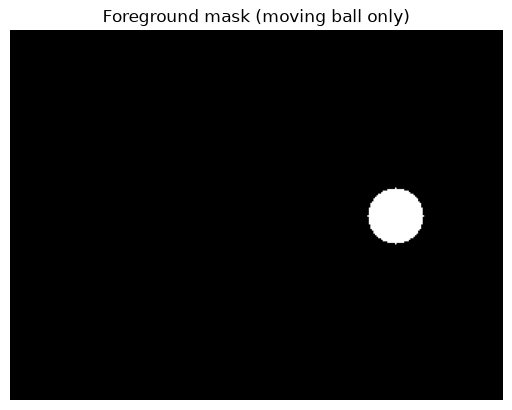

In [2]:
frames = []
for i in range(30):
    f = np.full((240, 320, 3), 230, np.uint8)
    cv2.rectangle(f, (30, 170), (290, 200), (180, 180, 180), -1)   # static 'road'
    cv2.circle(f, (25 + i * 9, 120), 18, (0, 0, 255), -1)          # moving ball
    frames.append(f)
mog2 = cv2.createBackgroundSubtractorMOG2(history=20, varThreshold=40, detectShadows=False)
for f in frames[:15]:
    mog2.apply(f)   # let it learn the background
mask = mog2.apply(frames[25])
print("Foreground pixels in frame 25:", int((mask > 0).sum()))
show(mask, "Foreground mask (moving ball only)")

## From foreground mask to moving-object box

Clean the mask with morphology, find contours, and box the largest one - the standard motion-detection chain. The centroid of that contour tracked over frames gives a trajectory.

Moving object box: (233, 103, 35, 35) | area: 954.0


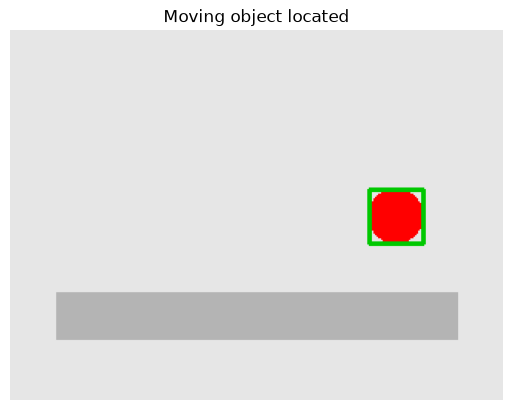

In [3]:
mask_clean = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
cs, _ = cv2.findContours(mask_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
if cs:
    biggest = max(cs, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(biggest)
    out = frames[25].copy()
    cv2.rectangle(out, (x, y), (x + w, y + h), (0, 200, 0), 2)
    print("Moving object box:", (x, y, w, h), "| area:", cv2.contourArea(biggest))
    show(out, "Moving object located")

## Lucas-Kanade optical flow

Optical flow estimates where points moved between two frames. The Lucas-Kanade method tracks sparse points (usually Shi-Tomasi corners) assuming small motion and constant brightness. Status 1 means the point was tracked successfully.

In [4]:
prev = cv2.cvtColor(frames[10], cv2.COLOR_BGR2GRAY)
nxt = cv2.cvtColor(frames[12], cv2.COLOR_BGR2GRAY)
points = cv2.goodFeaturesToTrack(prev, 30, 0.01, 10)
new_points, status, _ = cv2.calcOpticalFlowPyrLK(prev, nxt, points, None)
moved = new_points[status.ravel() == 1] - points[status.ravel() == 1]
print("Points tracked:", int(status.sum()), "of", len(points))
print("Median motion (dx, dy):", np.round(np.median(moved.reshape(-1, 2), axis=0), 1), "pixels over 2 frames")

Points tracked: 12 of 12
Median motion (dx, dy): [18. -0.] pixels over 2 frames


## Drawing flow tracks

Accumulating the tracked positions frame after frame draws motion trails - the visual basis of object tracking, action analysis and video stabilisation.

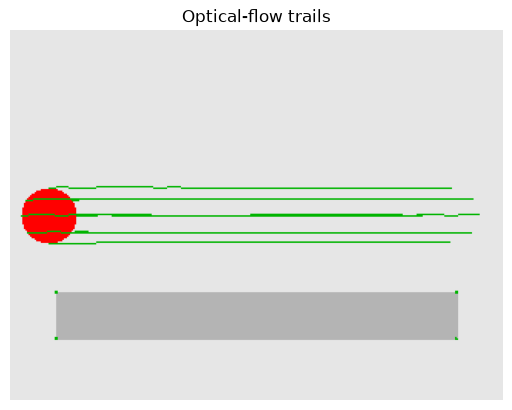

In [5]:
track_img = frames[0].copy()
pts = cv2.goodFeaturesToTrack(cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY), 30, 0.01, 10)
old_gray = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
for f in frames[1:]:
    g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
    new_pts, st, _ = cv2.calcOpticalFlowPyrLK(old_gray, g, pts, None)
    for new, old in zip(new_pts[st.ravel() == 1], pts[st.ravel() == 1]):
        cv2.line(track_img, tuple(old.ravel().astype(int)), tuple(new.ravel().astype(int)), (0, 180, 0), 1)
    old_gray, pts = g, new_pts
show(track_img, "Optical-flow trails")

## QR code detection and decoding

`cv2.QRCodeDetector` finds and decodes QR codes in one call, returning the text, the corner points and a straightened image. We generate a real QR code with OpenCV's own encoder when available, then decode it - a full round trip.

Decoded: 'Computer Vision notes - OpenCV section'
Corners found: True


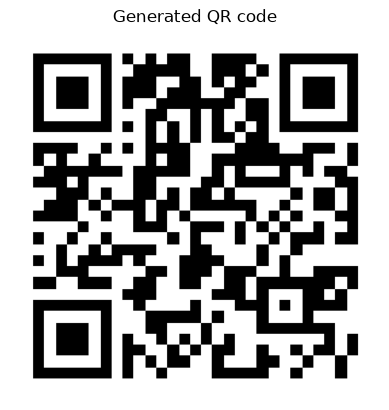

In [6]:
try:
    encoder = cv2.QRCodeEncoder.create()
    qr_img = encoder.encode("Computer Vision notes - OpenCV section")
    qr_big = cv2.resize(qr_img, (240, 240), interpolation=cv2.INTER_NEAREST)
    detector = cv2.QRCodeDetector()
    data, points, _ = detector.detectAndDecode(qr_big)
    print("Decoded:", repr(data))
    print("Corners found:", points is not None)
    show(qr_big, "Generated QR code")
except cv2.error as e:
    print("QR encoder not available in this OpenCV build:", e)

## Barcode and multi-code detection

`detectAndDecodeMulti` handles several codes in one image and also works for many barcode formats. In production, codes are usually sharpened/upscaled first - detection improves a lot on larger, high-contrast inputs.

In [7]:
try:
    ok, infos, points, _ = detector.detectAndDecodeMulti(qr_big)
    print("Multi-detect success:", ok, "| codes:", infos)
except (cv2.error, NameError) as e:
    print("Multi-detect skipped:", e)

Multi-detect success: True | codes: ('Computer Vision notes - OpenCV section',)


## Key Points

- MOG2 learns the static scene; its output mask marks moving pixels.
- Mask -> morphology -> contours -> box is the standard motion-detection chain.
- Lucas-Kanade optical flow tracks sparse corner points between frames.
- Flow needs small motion and texture; it fails on blank or fast-moving regions.
- QRCodeDetector detects and decodes in one call; upscaling small codes helps.
- detectAndDecodeMulti handles several codes at once.

## Mini Task

1. Run MOG2 on frames where the ball moves vertically instead and box the ball in the last frame.
2. Track the ball's centroid over 10 frames and print the trajectory.
3. Encode your name as a QR code, decode it back, and verify the text matches.